✅ Diccionario local cargado: 370 pacientes base mapeados.
✅ ¡Cruce completado! Tenemos 97 pacientes listos para la gráfica de supervivencia.


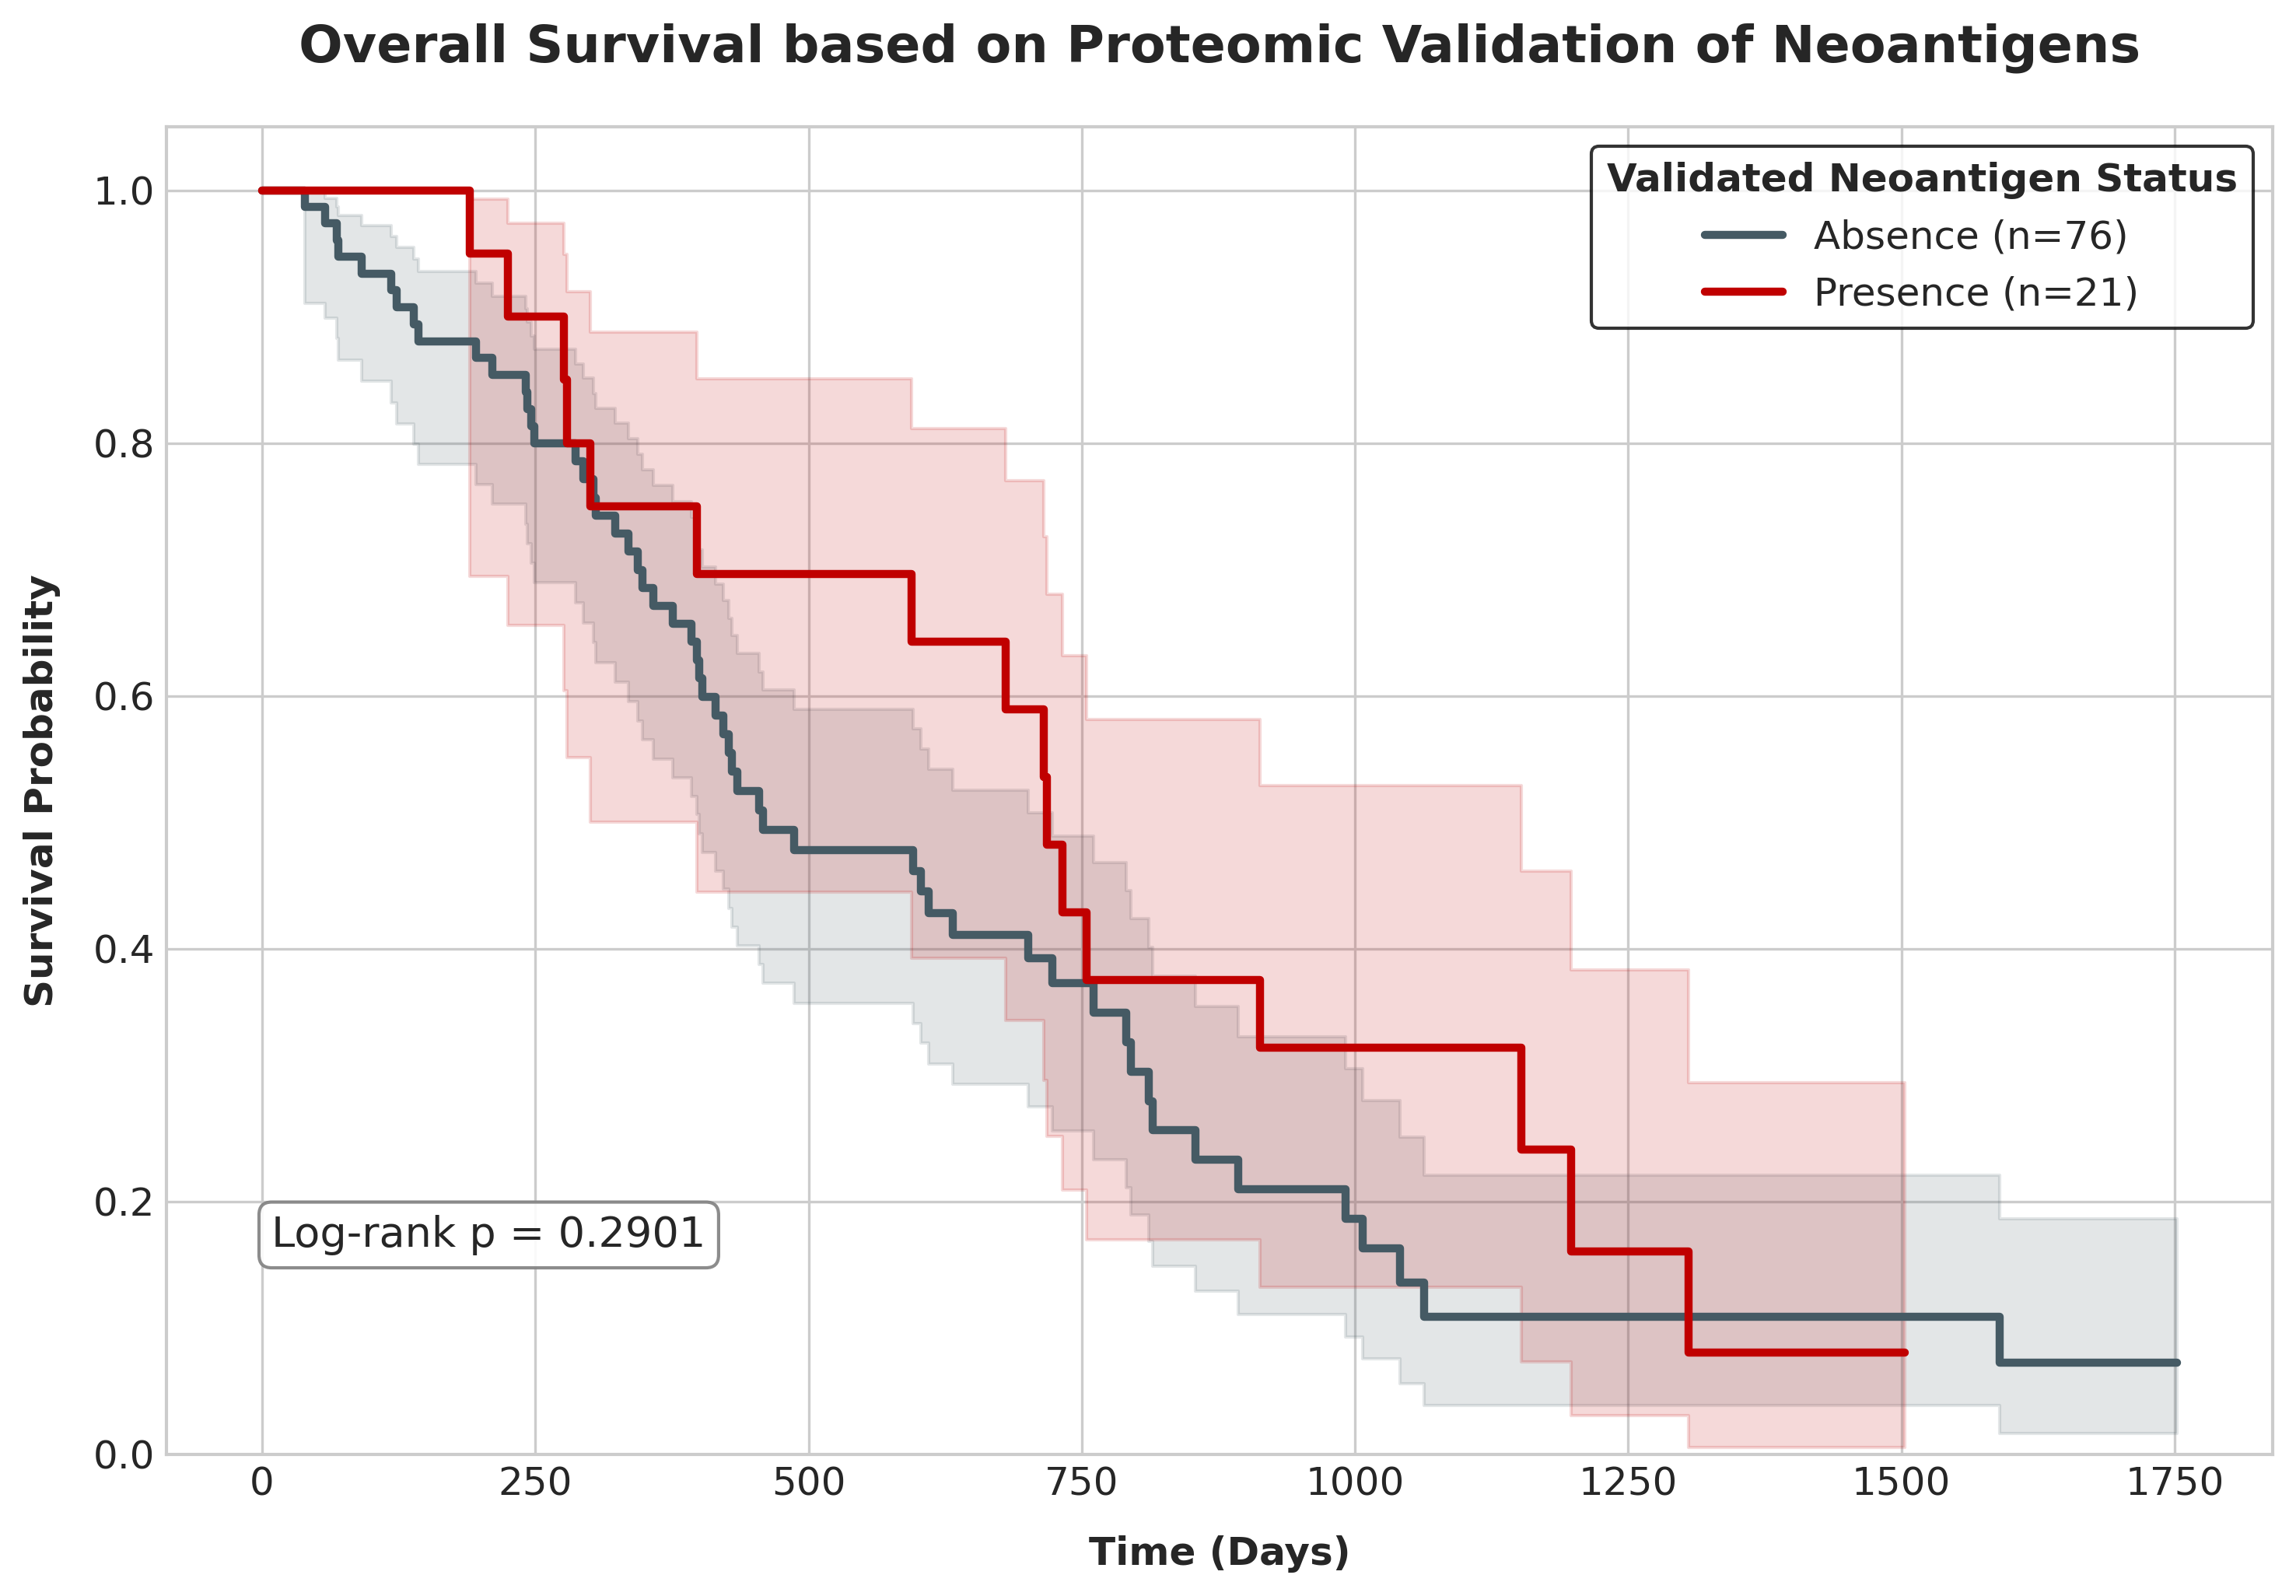

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from matplotlib import rcParams

# ==============================================================================
# 0. LA PIEDRA ROSETTA: CARGAR EL MAPEO LOCAL (SIN INTERNET)
# ==============================================================================
ruta_mapping = "../data/interim/proteomal/case_aliquot_mapping.csv" # <-- Ajusta tu ruta si es distinta
df_map = pd.read_csv(ruta_mapping)

# Creamos un diccionario rápido usando solo los 10 primeros caracteres (La raíz del paciente)
diccionario_prefijos = {}
for _, row in df_map.iterrows():
    case_id = row['case_id']
    aliquot = str(row['aliquot_submitter_id'])
    if aliquot.startswith('CPT'):
        diccionario_prefijos[aliquot[:10]] = case_id

print(f"✅ Diccionario local cargado: {len(diccionario_prefijos)} pacientes base mapeados.")

# ==============================================================================
# 1. CÁLCULO DE LA CARGA DE NEOANTÍGENOS (NEOANTIGEN BURDEN)
# ==============================================================================
df_prot = pd.read_csv("../data/processed/Proteomics_Eval_outputs/Neoantigenos_por_Paciente_CPTAC.csv")
df_prot['Z_Score'] = df_prot.groupby(['Batch', 'Neoantigeno'])['Abundancia_TMT'].transform(lambda x: zscore(x, ddof=1) if len(x)>1 else 0)

df_burden = pd.DataFrame({'Paciente_RAW': df_prot['Paciente'].unique()})

def traducir_paciente(paciente_raw):
    paciente_str = str(paciente_raw)
    
    # 1. Traducir usando tu CSV (cortando a 10 caracteres)
    if paciente_str.startswith('CPT'):
        prefijo = paciente_str[:10]
        if prefijo in diccionario_prefijos:
            return diccionario_prefijos[prefijo]
    
    # 2. Si ya viene limpio como C3L-01687, lo dejamos bonito
    partes = paciente_str.split('-')
    if len(partes) >= 3 and partes[0] in ['C3L', 'C3N']:
        return f"{partes[0]}-{partes[1]}"
    
    return paciente_raw 

df_burden['case_id'] = df_burden['Paciente_RAW'].apply(traducir_paciente)

# Contamos los positivos (Z>=2.0)
df_pos = df_prot[df_prot['Z_Score'] >= 2.0]
conteo = df_pos.groupby('Paciente')['Neoantigeno'].nunique().reset_index()
conteo.columns = ['Paciente_RAW', 'Num_Neoantigenos']

df_burden = pd.merge(df_burden, conteo, on='Paciente_RAW', how='left').fillna(0)

# Agrupamos por Case ID
df_burden_clean = df_burden.groupby('case_id')['Num_Neoantigenos'].max().reset_index()
df_burden_clean['Grupo_Inmune'] = np.where(df_burden_clean['Num_Neoantigenos'] > 0, 'Presence (≥1 Neoantigen)', 'Absence (0 Neoantigens)')

# ==============================================================================
# 2. CARGA Y CRUCE DE DATOS CLÍNICOS
# ==============================================================================
ruta_clinica = "../data/raw/supervivencia_pdac.txt" 
df_clinico = pd.read_csv(ruta_clinica, sep='\t')

df_clinico['OS_days'] = pd.to_numeric(df_clinico['OS_days'], errors='coerce')
df_clinico['OS_event'] = pd.to_numeric(df_clinico['OS_event'], errors='coerce')

df_final = pd.merge(df_burden_clean, df_clinico, on='case_id', how='inner')
df_final = df_final.dropna(subset=['OS_days', 'OS_event'])

print(f"✅ ¡Cruce completado! Tenemos {len(df_final)} pacientes listos para la gráfica de supervivencia.")

# ==============================================================================
# 3. ANÁLISIS DE SUPERVIVENCIA Y GRÁFICA
# ==============================================================================
grupo_presencia = df_final[df_final['Grupo_Inmune'] == 'Presence (≥1 Neoantigen)']
grupo_ausencia = df_final[df_final['Grupo_Inmune'] == 'Absence (0 Neoantigens)']

T_presencia, E_presencia = grupo_presencia['OS_days'], grupo_presencia['OS_event']
T_ausencia, E_ausencia = grupo_ausencia['OS_days'], grupo_ausencia['OS_event']

if len(grupo_presencia) == 0 or len(grupo_ausencia) == 0:
    print("⚠️ Error: Uno de los grupos de pacientes está vacío tras el cruce.")
else:
    resultados_lr = logrank_test(T_presencia, T_ausencia, event_observed_A=E_presencia, event_observed_B=E_ausencia)
    p_valor = resultados_lr.p_value

    plt.style.use('seaborn-v0_8-whitegrid')
    rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12, 'figure.dpi': 300})
    fig, ax = plt.subplots(figsize=(10, 7))
    kmf = KaplanMeierFitter()

    kmf.fit(T_ausencia, event_observed=E_ausencia, label=f'Absence (n={len(grupo_ausencia)})')
    kmf.plot_survival_function(ax=ax, color='#455a64', linewidth=2.5, ci_show=True, ci_alpha=0.15)

    kmf.fit(T_presencia, event_observed=E_presencia, label=f'Presence (n={len(grupo_presencia)})')
    kmf.plot_survival_function(ax=ax, color='#c00000', linewidth=2.5, ci_show=True, ci_alpha=0.15)

    ax.set_title("Overall Survival based on Proteomic Validation of Neoantigens", pad=20, fontweight='bold', fontsize=16)
    ax.set_xlabel("Time (Days)", fontweight='bold', labelpad=10)
    ax.set_ylabel("Survival Probability", fontweight='bold', labelpad=10)
    ax.set_ylim([0.0, 1.05])

    p_val_text = f"Log-rank p = {p_valor:.4f}"
    if p_valor < 0.05:
        p_val_text += "\n(Statistically Significant *)"

    ax.text(0.05, 0.15, p_val_text, transform=ax.transAxes, fontsize=13, 
            verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))

    ax.legend(loc='upper right', frameon=True, edgecolor='black', title="Validated Neoantigen Status", title_fontproperties={'weight':'bold'})

    plt.tight_layout()
    plt.savefig('../results/figures/proteomics_characterization/Figure_KaplanMeier_Survival.png', dpi=300, bbox_inches='tight')
    plt.show()

Columnas en tu Excel (revisa los nombres para el bloque de abajo):
['case_id', 'tumor_included_for_the_study', 'normal_included_for_the_study', 'histology_diagnosis', 'age', 'sex', 'race', 'participant_country', 'tumor_site', 'tumor_focality', 'tumor_size_cm', 'tumor_necrosis', 'lymph_vascular_invasion', 'perineural_invasion', 'number_of_lymph_nodes_examined', 'number_of_lymph_nodes_positive_for_tumor', 'pathologic_staging_regional_lymph_nodes_pn', 'pathologic_staging_primary_tumor_pt', 'pathologic_staging_distant_metastasis_pm', 'clinical_staging_distant_metastasis_cm', 'residual_tumor', 'tumor_stage_pathological', 'additional_pathologic_findings', 'bmi', 'alcohol_consumption', 'tobacco_smoking_history', 'medical_condition', 'Neoplastic_cellularity', 'Acinar_fraction', 'Islet_fraction', 'Stromal_fraction', 'Non_neoplastic_duct', 'Fat_fraction', 'Inflammation_fraction', 'Muscle_fraction', 'follow_up_days', 'vital_status', 'is_this_patient_lost_to_follow_up', 'cause_of_death']

✅ Datos 

<lifelines.CoxPHFitter: fitted with 95 total observations, 26 right-censored observations>
             duration col = 'OS_days'
                event col = 'OS_event'
      baseline estimation = breslow
   number of observations = 95
number of events observed = 69
   partial log-likelihood = -244.43
         time fit was run = 2026-03-16 12:06:08 UTC

---
                                    coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                           
Neoantigen_Presence                -0.53      0.59      0.33           -1.17            0.12                0.31                1.13
age                                 0.01      1.01      0.01           -0.02            0.03                0.98                1.03
sex_Male                           -0.78      0.46      0.29           -1.35           -0.22                0.26                0.80
tumor_stage_pathological_Stage IB  -1.14      0.32      0.74           -2.58            0.31                0.08                1.36
tumor_stage_pathological_Stage IIA  0.42      1.53      0.75           -1.04            1.89                0.35                6.62
tumor_stage_pathological_Stage IIB -0.76      0.47      0.65           -2.02            0.51                0.13                1.66
tumor_stage_pathological_Stage III -0.70      0.50      0.66           -1.99            0.60                0.14                1.82
tumor_stage_pathological_Stage IV   1.17      3.24      0.71           -0.23            2.58                0.80               13.13

                                    cmp to     z    p  -log2(p)
covariate                                                      
Neoantigen_Presence                   0.00 -1.59 0.11      3.16
age                                   0.00  0.54 0.59      0.76
sex_Male                              0.00 -2.71 0.01      7.22
tumor_stage_pathological_Stage IB     0.00 -1.54 0.12      3.02
tumor_stage_pathological_Stage IIA    0.00  0.57 0.57      0.81
tumor_stage_pathological_Stage IIB    0.00 -1.17 0.24      2.05
tumor_stage_pathological_Stage III    0.00 -1.05 0.29      1.77
tumor_stage_pathological_Stage IV     0.00  1.64 0.10      3.32
---
Concordance = 0.65
Partial AIC = 504.86
log-likelihood ratio test = 23.84 on 8 df
-log2(p) of ll-ratio test = 8.68

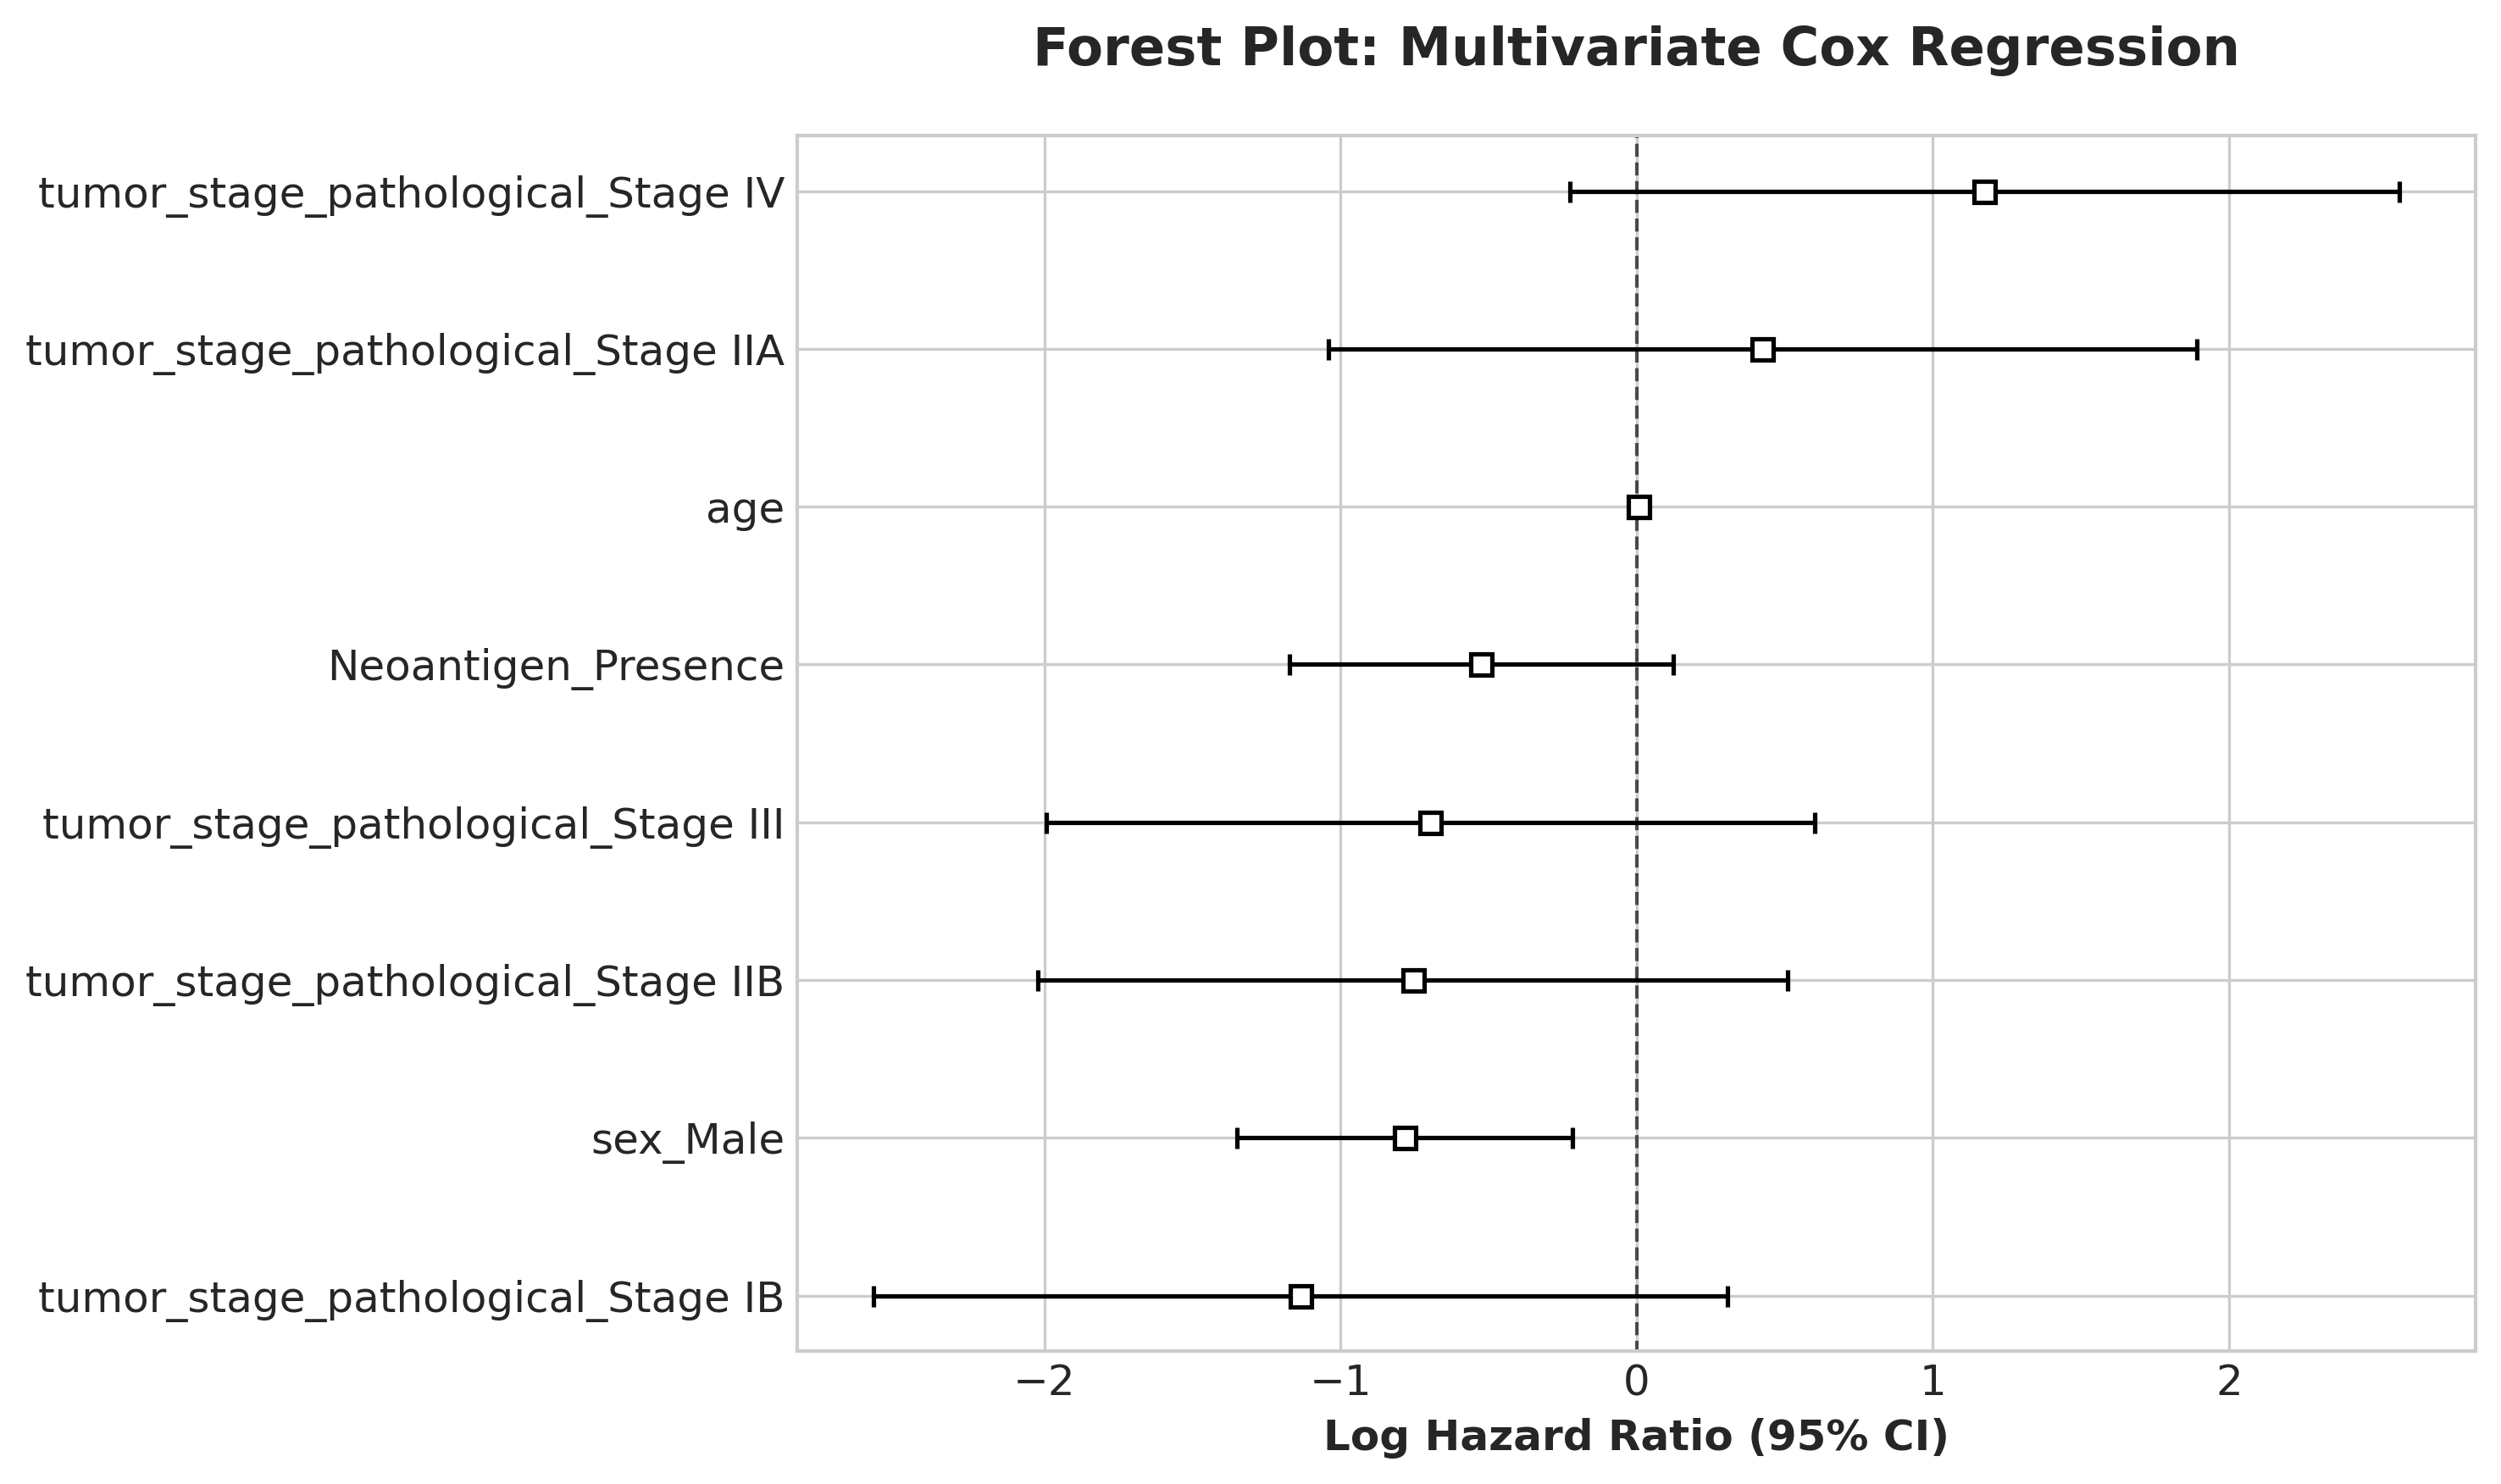

In [10]:
from lifelines import CoxPHFitter

# ==============================================================================
# 4. CARGA DE COVARIABLES CLÍNICAS DESDE EXCEL
# ==============================================================================
ruta_excel = "../data/raw/mmc1.xlsx" 
df_excel_clinico = pd.read_excel(ruta_excel, sheet_name='Clinical_data')

print("Columnas en tu Excel (revisa los nombres para el bloque de abajo):")
print(df_excel_clinico.columns.tolist())

# ⚠️ AJUSTA ESTOS NOMBRES SEGÚN LO QUE HAYA IMPRESO LA LÍNEA ANTERIOR ⚠️
col_paciente_excel = 'case_id'     # Puede que se llame 'Case ID', 'Patient ID', etc.
col_edad           = 'age'         # Nombre de la columna de edad
col_sexo           = 'sex'      # Nombre de la columna de sexo
col_estadio        = 'tumor_stage_pathological'       # Nombre de la columna de estadio del tumor

# Extraemos solo lo necesario para no ensuciar el dataframe
df_covariables = df_excel_clinico[[col_paciente_excel, col_edad, col_sexo, col_estadio]].copy()

# Renombramos la columna del paciente para que coincida con df_final y poder cruzar
df_covariables = df_covariables.rename(columns={col_paciente_excel: 'case_id'})

# ==============================================================================
# 5. PREPARACIÓN DEL DATAFRAME PARA EL MODELO COX MULTIVARIANTE
# ==============================================================================
# Cruzamos tu df_final (que ya tiene OS_days y OS_event) con las covariables
df_cox_full = pd.merge(df_final, df_covariables, on='case_id', how='inner')

# Convertimos tu variable objetivo de Neoantígenos a formato binario numérico (0 y 1)
df_cox_full['Neoantigen_Presence'] = np.where(df_cox_full['Grupo_Inmune'] == 'Presence (≥1 Neoantigen)', 1, 0)

# Seleccionamos las columnas estrictamente necesarias para el modelo
cols_modelo = ['OS_days', 'OS_event', 'Neoantigen_Presence', col_edad, col_sexo, col_estadio]
df_cox = df_cox_full[cols_modelo].copy()

# 1. El modelo de Cox NO tolera nulos (NaN). Limpiamos pacientes incompletos.
df_cox = df_cox.dropna()

# 2. Convertimos variables de texto (Sexo, Estadio) en "Dummies" binarias (0 y 1)
# drop_first=True evita colinealidad matemática perfecta
df_cox = pd.get_dummies(df_cox, columns=[col_sexo, col_estadio], drop_first=True)

# 3. Convertimos todo a float o int para asegurar que lifelines no se queje de booleanos
for col in df_cox.columns:
    df_cox[col] = pd.to_numeric(df_cox[col])

print(f"\n✅ Datos preparados para Cox. N final de pacientes: {len(df_cox)}")

# ==============================================================================
# 6. ENTRENAMIENTO Y VISUALIZACIÓN DEL MODELO COX
# ==============================================================================
cph = CoxPHFitter()

try:
    # Ajustamos el modelo de riesgos proporcionales
    cph.fit(df_cox, duration_col='OS_days', event_col='OS_event')
    
    # Imprimimos la tabla estadística
    print("\n" + "="*60)
    print("RESULTADOS DEL MODELO DE COX MULTIVARIANTE")
    print("="*60)
    cph.print_summary()
    
    # Visualizamos el Forest Plot
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, ax = plt.subplots(figsize=(10, 6))
    cph.plot(ax=ax)
    
    ax.set_title("Forest Plot: Multivariate Cox Regression", pad=20, fontweight='bold', fontsize=15)
    ax.set_xlabel("Log Hazard Ratio (95% CI)", fontweight='bold')
    
    plt.tight_layout()
    plt.savefig('../results/figures/proteomics_characterization/Figure_Cox_ForestPlot.png', dpi=300, bbox_inches='tight')
    plt.show()

except Exception as e:
    print(f"\n❌ Ha ocurrido un error al ajustar el modelo: {e}")
    print("Revisa si alguna variable categórica (como el estadio) tiene una sola categoría o causa colinealidad.")